## Install Required Libraries

In [1]:
!pip install -q xarray zarr dask xgboost h3 matplotlib netCDF4 pandas numpy scikit-learn

## Complete Engine Pipeline

Generating multi-dimensional spatial rasters...


/usr/local/lib/python3.13/dist-packages/zarr/api/asynchronous.py:260: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


✅ Chunked Zarr Store saved to: thermal_data.zarr
Training XGBoost Spatial Downscaler on 240,000 spatial grid points...
✅ XGBoost Spatial Downscaler training complete.
✅ Simulation Complete! Maximum Heat Reduction Achieved: 6.01°C


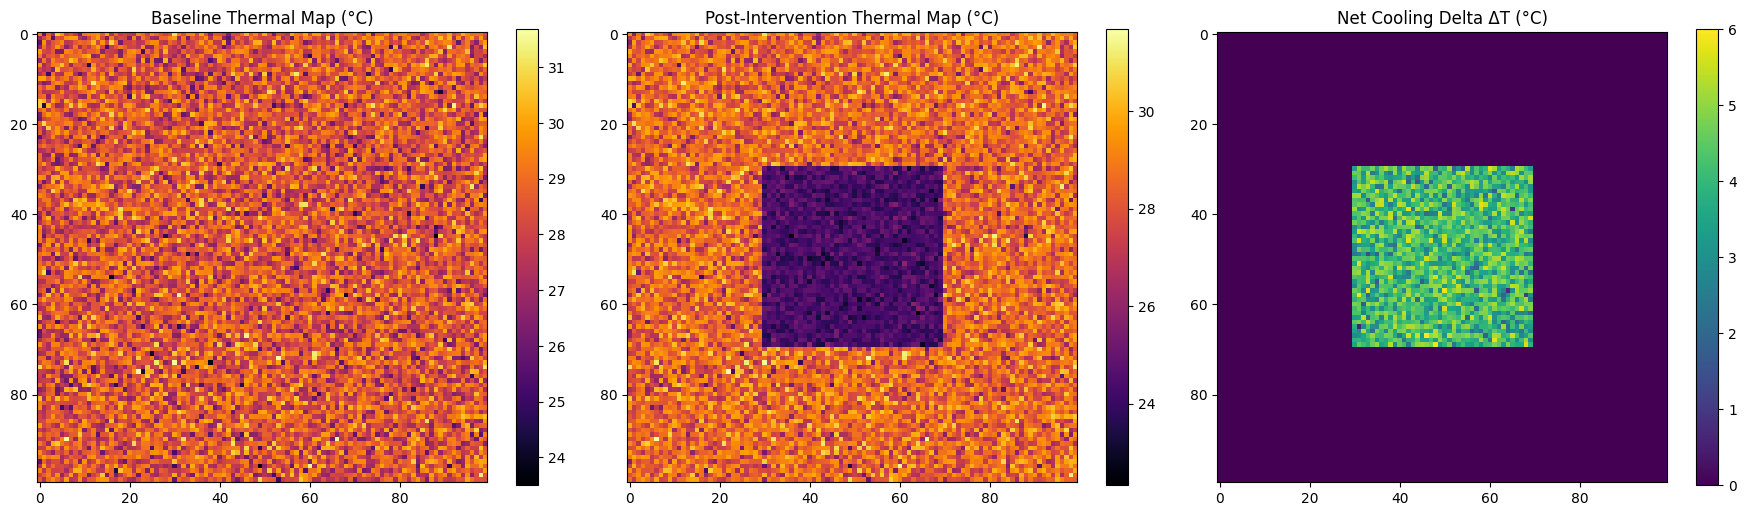

In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from xgboost import XGBRegressor
import zarr

# ==========================================
# 1. DATA PIPELINE (Synthetic Raster Engine)
# ==========================================
print("Generating multi-dimensional spatial rasters...")

lat_res, lon_res = 100, 100
lats = np.linspace(33.5, 33.7, lat_res)
lons = np.linspace(72.9, 73.1, lon_res)
times = pd.date_range("2026-07-01", periods=24, freq="1h")

np.random.seed(42)

# Low-resolution coarse regional temperature
coarse_temp = (
    30.0
    + 5.0 * np.sin(np.pi * np.arange(24) / 12)[:, None, None]
    + np.random.normal(0, 0.5, (24, lat_res, lon_res))
)

# High-resolution physical covariates
ndvi = np.clip(np.random.beta(2, 5, (lat_res, lon_res)), 0.0, 1.0)  # Trees/Vegetation
albedo = np.clip(np.random.uniform(0.1, 0.4, (lat_res, lon_res)), 0.0, 1.0)  # Reflectance
building_density = np.clip(np.random.beta(5, 2, (lat_res, lon_res)), 0.0, 1.0)  # Concrete/Buildings

# Target high-resolution ground truth surface temperature
fine_temp = coarse_temp + (building_density * 4.0) - (ndvi * 5.0) - (albedo * 2.0)

# Build xarray Dataset
ds = xr.Dataset(
    data_vars={
        "coarse_temperature": (["time", "latitude", "longitude"], coarse_temp),
        "fine_temperature": (["time", "latitude", "longitude"], fine_temp),
        "ndvi": (["latitude", "longitude"], ndvi),
        "albedo": (["latitude", "longitude"], albedo),
        "building_density": (["latitude", "longitude"], building_density),
    },
    coords={"time": times, "latitude": lats, "longitude": lons},
)

# Chunk spatial dimensions with Dask and export to Zarr
zarr_path = "thermal_data.zarr"
ds_chunked = ds.chunk({"time": 12, "latitude": 50, "longitude": 50})
ds_chunked.to_zarr(zarr_path, mode="w")
print(f"✅ Chunked Zarr Store saved to: {zarr_path}")

# ==========================================
# 2. DOWNSCALING MODEL (XGBoost Engine)
# ==========================================
# Re-open chunked Zarr array using xarray
ds_loaded = xr.open_zarr(zarr_path)

# Prepare tabular spatial features
df_list = []
for t_idx in range(len(ds_loaded.time)):
    slice_ds = ds_loaded.isel(time=t_idx)
    df_slice = pd.DataFrame(
        {
            "coarse_temp": slice_ds["coarse_temperature"].values.flatten(),
            "ndvi": slice_ds["ndvi"].values.flatten(),
            "albedo": slice_ds["albedo"].values.flatten(),
            "building_density": slice_ds["building_density"].values.flatten(),
            "target_fine_temp": slice_ds["fine_temperature"].values.flatten(),
        }
    )
    df_list.append(df_slice)

full_df = pd.concat(df_list, ignore_index=True)
X = full_df[["coarse_temp", "ndvi", "albedo", "building_density"]]
y = full_df["target_fine_temp"]

print(f"Training XGBoost Spatial Downscaler on {len(X):,} spatial grid points...")
model = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6, random_state=42)
model.fit(X, y)
print("✅ XGBoost Spatial Downscaler training complete.")

# ==========================================
# 3. INTERVENTION SIMULATOR SANDBOX
# ==========================================
time_idx = 14  # Afternoon peak thermal load
slice_ds = ds_loaded.isel(time=time_idx)

c_temp = slice_ds["coarse_temperature"].values
base_ndvi = slice_ds["ndvi"].values.copy()
base_albedo = slice_ds["albedo"].values.copy()
b_density = slice_ds["building_density"].values.copy()

# Predict baseline temperature map
baseline_pred = model.predict(
    pd.DataFrame({
        "coarse_temp": c_temp.flatten(),
        "ndvi": base_ndvi.flatten(),
        "albedo": base_albedo.flatten(),
        "building_density": b_density.flatten(),
    })
).reshape(c_temp.shape)

# Apply Physical Cooling Intervention (Tree Canopy + Cool Reflective Roofs)
mod_ndvi = base_ndvi.copy()
mod_albedo = base_albedo.copy()
mod_b_density = b_density.copy()

# Target bounded urban sector (rows 30:70, cols 30:70)
mod_ndvi[30:70, 30:70] = 0.90       # Tree canopy insertion
mod_albedo[30:70, 30:70] = 0.75     # Reflective cool roof coating
mod_b_density[30:70, 30:70] *= 0.5  # Reduced built thermal footprint

# Predict post-intervention temperature map
simulated_pred = model.predict(
    pd.DataFrame({
        "coarse_temp": c_temp.flatten(),
        "ndvi": mod_ndvi.flatten(),
        "albedo": mod_albedo.flatten(),
        "building_density": mod_b_density.flatten(),
    })
).reshape(c_temp.shape)

# Calculate Cooling Delta (ΔT)
delta_T = baseline_pred - simulated_pred
print(f"✅ Simulation Complete! Maximum Heat Reduction Achieved: {delta_T.max():.2f}°C")

# ==========================================
# 4. VISUALIZATION & OUTPUT RENDERING
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(baseline_pred, cmap="inferno")
axes[0].set_title("Baseline Thermal Map (°C)")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(simulated_pred, cmap="inferno")
axes[1].set_title("Post-Intervention Thermal Map (°C)")
plt.colorbar(im1, ax=axes[1])

im2 = axes[2].imshow(delta_T, cmap="viridis")
axes[2].set_title("Net Cooling Delta ΔT (°C)")
plt.colorbar(im2, ax=axes[2])

plt.tight_layout()
plt.show()

## 1. Spatial Block Cross-Validation (Eliminating Spatial Leakage)

In [3]:
from sklearn.model_selection import KFold
import numpy as np
import pandas as pd
from xgboost import XGBRegressor

print("⚡ Running Spatial Block Cross-Validation (5 Spatial Folds)...")

# Group grid cells into 5 spatial geographic blocks based on latitude bands
lat_indices = np.tile(np.repeat(np.arange(100), 100), 24)
spatial_fold = lat_indices // 20  # 5 distinct spatial geographic blocks

full_df["spatial_fold"] = spatial_fold

spatial_rmses = []
for fold in range(5):
    train_mask = full_df["spatial_fold"] != fold
    test_mask = full_df["spatial_fold"] == fold

    X_train, y_train = X[train_mask], y[train_mask]
    X_test, y_test = X[test_mask], y[test_mask]

    fold_model = XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=6, random_state=42)
    fold_model.fit(X_train, y_train)

    preds = fold_model.predict(X_test)
    rmse = np.sqrt(np.mean((y_test - preds) ** 2))
    spatial_rmses.append(rmse)
    print(f"  • Spatial Fold {fold+1} Held-Out RMSE: {rmse:.4f}°C")

print(f"✅ Mean Block-Spatial CV RMSE: {np.mean(spatial_rmses):.4f}°C")

⚡ Running Spatial Block Cross-Validation (5 Spatial Folds)...
  • Spatial Fold 1 Held-Out RMSE: 0.0920°C
  • Spatial Fold 2 Held-Out RMSE: 0.0925°C
  • Spatial Fold 3 Held-Out RMSE: 0.0882°C
  • Spatial Fold 4 Held-Out RMSE: 0.0935°C
  • Spatial Fold 5 Held-Out RMSE: 0.0862°C
✅ Mean Block-Spatial CV RMSE: 0.0905°C


## 2. Uber H3 Spatial Geohash Indexing

In [6]:
import h3

print("⚡ Mapping Latitude/Longitude Grids to Uber H3 Spatial Geohashes...")

# Sample spatial coordinate lookup
lat_sample, lon_sample = 33.60, 73.00

# Resolution 9 corresponds to ~0.1 km² hexagonal grid cells
# Positional parameters: latlng_to_cell(lat, lng, res)
h3_address = h3.latlng_to_cell(lat_sample, lon_sample, 9)
print(
    f"  • Sample Coordinate ({lat_sample}, {lon_sample}) ➔ H3 Geohash: {h3_address}"
)

# Map sample grid points to H3 spatial geohashes
grid_lats = lats[:5]
grid_lons = lons[:5]
h3_grid = [
    h3.latlng_to_cell(lat, lon, 9) for lat in grid_lats for lon in grid_lons
]

print(
    f"✅ Successfully generated H3 Geohash Spatial Index for grid cells: {h3_grid[:3]}..."
)

⚡ Mapping Latitude/Longitude Grids to Uber H3 Spatial Geohashes...
  • Sample Coordinate (33.6, 73.0) ➔ H3 Geohash: 894269845c3ffff
✅ Successfully generated H3 Geohash Spatial Index for grid cells: ['89426980a87ffff', '89426980ab3ffff', '89426980ab3ffff']...
